# F05 — Predicted paleolatitude from an APWP vs a `gplately` paleo-site


**Cluster F: Paleomagnetism.**
**Compute paleolatitude at one location through the Cenozoic two ways — from the global apparent polar wander path (APWP) of Vaes et al. (2023), which lives in the paleomagnetic reference frame, and from a `gplately` reconstruction of the same site in the Zahirovic 2022 plate model (default mantle reference frame) — and compare. The gap between the two curves is dominated by true polar wander, and the notebook adds the model's own paleomagnetic frame as a third curve to show how the gap closes when both are expressed in the same frame.**

## What this notebook produces

A single locality — by default Cairo (30.0°N, 31.2°E) on the African plate (701) — swept through reconstruction ages from 0 to 100 Ma. At each age we compute the paleolatitude of the site in three ways:

1. **APWP** (bundled, *paleomagnetic frame*): paleolatitude from the great-circle distance between the site and the interpolated Vaes et al. (2023) global APWP pole at that age. The APWP is given in South African coordinates (plate 701), so it applies directly to a site on the African plate. Longitudes are unwrapped before interpolation so values either side of the 0/360 cut do not produce a spurious mid-arc pole.
2. **gplately Zahirovic 2022, default frame** (*mantle reference frame*): paleolatitude from `gplately.Points.reconstruct(time, return_array=True)`.
3. **gplately Zahirovic 2022, paleomagnetic frame** (anchor plate 701701, the model's built-in paleomagnetic frame; see F01 and F02): the same reconstruction expressed in a paleomagnetic frame, so that it can be compared with the APWP like with like. This curve is skipped if the rotation file does not contain plate 701701.

The paleolatitudes are plotted as a function of age. The gap between the APWP and the default-frame curve is an estimate of *true polar wander* at the site over the time window: the rotation of the whole lithosphere + mantle relative to the spin axis, which a mantle frame does not see but a paleomagnetic frame does.

The notebook also demonstrates the **longitudes-first return-order gotcha** in `Points.reconstruct(return_array=True)` — unpacking as `(rlats, rlons)` silently mis-plots the site into the wrong hemisphere.

**Why Cairo and not Cape Verde?** The default site matters. A site close to the Euler pole that describes the offset between two frames hardly changes paleolatitude and can show both southward and northward motion, which makes a poor reference location. Cape Verde (16°N, 25°W) behaves like this for the Cenozoic, whereas Cairo gives a clean curve; both sites are easy to try by editing the configuration cell.

**Audience**: postgrad.
**Difficulty**: ★★☆.

## Learning objectives

- Load a tabulated APWP and compute the predicted paleolatitude at an arbitrary site/age from the pole–site great-circle distance (`paleolat = 90 - p`), with proper longitude unwrapping.
- Use `gplately.Points.reconstruct(time, return_array=True)` to compute the paleo-position of a present-day point at the same set of ages.
- Identify which **absolute reference frame** each curve lives in (mantle vs. paleomagnetic) and read the inter-curve gap as a TPW estimate.
- Avoid the lon-first return-order gotcha.

## Prerequisites and runtime

- Plate model: Zahirovic 2022 default (0–410 Ma covers the Cenozoic).
- Python: `gplately`, `pygmt`, `numpy`, `pandas`.
- Bundled data: `data/paleomag/vaes2023_global_apwp.csv` (global APWP of Vaes et al., 2023, 0–320 Ma, South African plate (701) coordinates, pole positions rounded to one decimal; columns `age`, `pole_lat`, `pole_lon`, `A95`).
- Runtime: a few seconds end-to-end.


In [1]:
# Defensive cwd fix: when Jupyter runs this notebook from Notebooks/, the
# `data/...` relative paths used below would not resolve. Step up to the
# suite root once so every `data/...` literal in the rest of the notebook
# finds its file. Idempotent — only runs if `../data` exists and `./data`
# doesn't.
import os as _os
from pathlib import Path as _Path
if _Path("../data").exists() and not _Path("data").exists():
    _os.chdir("..")

# Cell 1 — imports
import numpy as np, pandas as pd
import gplately, pygmt, pygplates
from plate_model_manager import PlateModelManager
import sys as _sys
from pathlib import Path as _P
for _d in (_P("Notebooks"), _P("."), _P("../Notebooks")):
    if (_d / "pmm_local.py").exists():
        _sys.path.insert(0, str(_d.resolve())); break
from pmm_local import LocalFirstPMM   # uses the local cache if the model server is unreachable
from IPython.display import display, HTML
# Library versions (printed for reproducibility)
try:
    import gplately, pygmt, pygplates
    print(f"gplately {gplately.__version__}  pygmt {pygmt.__version__}  pygplates {pygplates.__version__}")
except Exception as _e:
    print(f"version probe failed: {_e}")


gplately 2.0.0.post19+git.2cce7bb3  pygmt v0.19.0  pygplates 1.0.0


## Configuration — change the site + age range here

In [2]:
# === USER CONFIGURATION =====================================================
MODEL_NAME = "Zahirovic2022"
SITE_LON, SITE_LAT = 31.2, 30.0       # Cairo, Africa plate (701); Cape Verde is (-25.0, 16.0)
PLATE_LABEL        = "Africa (plate 701)"   # human-readable label for the figure stamp
AGES = np.arange(0, 101, 5)           # Ma — sweep from 0 to 100 Ma
# ============================================================================


## 1. APWP-predicted paleolatitude at the site

We load the bundled global APWP of Vaes et al. (2023), interpolate the pole position to each requested age (with longitudes unwrapped first), and compute the predicted paleolatitude at the site from the pole–site great-circle distance:

$$\text{paleolat} \;=\; 90^\circ - \arccos\!\bigl(\sin\phi_s\sin\phi_p + \cos\phi_s\cos\phi_p\cos(\lambda_p - \lambda_s)\bigr)$$

This APWP-derived paleolatitude is implicitly in the **paleomagnetic reference frame**: the pole is the spin-axis direction at the moment of magnetisation expressed in present-day coordinates, and the great-circle distance recovers paleolatitude directly. The youngest pole of the path is at 1.4 Ma and is not exactly at the geographic pole, so the 0 Ma value differs slightly from the present-day latitude of the site.


In [3]:
# Cell 2 — APWP-predicted paleolatitude at the site (Vaes et al. 2023, paleomag frame)
# Bundled global APWP of Vaes et al. (2023, Earth-Science Reviews) in South
# African (plate 701) coordinates. Pole position is interpolated to each age
# (longitudes unwrapped first to avoid the 0/360 cut), then paleolatitude
# is computed from the pole–site great-circle distance:
#   p (deg)  = great-circle distance from site to pole
#   paleolat = 90 - p   (axial-dipole approximation)
APWP_CSV = "data/paleomag/vaes2023_global_apwp.csv"


def _paleolat_from_pole(site_lat, site_lon, pole_lat, pole_lon):
    slat, slon = np.radians(site_lat), np.radians(site_lon)
    plat, plon = np.radians(pole_lat), np.radians(pole_lon)
    cosp = (np.sin(slat) * np.sin(plat)
            + np.cos(slat) * np.cos(plat) * np.cos(plon - slon))
    return 90.0 - np.degrees(np.arccos(np.clip(cosp, -1.0, 1.0)))


apwp_table = pd.read_csv(APWP_CSV, comment="#")
apwp_age   = apwp_table["age"].values.astype(float)
apwp_plat  = apwp_table["pole_lat"].values.astype(float)
apwp_plon_unwrapped = np.degrees(np.unwrap(np.radians(
    apwp_table["pole_lon"].values.astype(float))))

apwp_paleolats = []
for t in AGES:
    pole_lat_t = float(np.interp(float(t), apwp_age, apwp_plat))
    pole_lon_t = float(np.interp(float(t), apwp_age, apwp_plon_unwrapped)) % 360.0
    apwp_paleolats.append(float(_paleolat_from_pole(
        SITE_LAT, SITE_LON, pole_lat_t, pole_lon_t)))
apwp_paleolats = np.array(apwp_paleolats)

apwp = pd.DataFrame({"age": AGES.astype(float),
                     "paleolat_apwp": apwp_paleolats})
apwp_label = "APWP Vaes 2023 (paleomag frame)"
print(f"Vaes 2023 APWP paleolat range: "
      f"{apwp['paleolat_apwp'].min():.2f}° to "
      f"{apwp['paleolat_apwp'].max():.2f}°")
apwp.head()


Vaes 2023 APWP paleolat range: 8.64° to 29.78°


,age,paleolat_apwp
0,0.0,29.775623
1,5.0,28.317598
2,10.0,26.890208
3,15.0,25.285560
4,20.0,23.580650


## 2. Reconstruction-predicted paleolatitude at the site

`gplately.Points.reconstruct(time, return_array=True)` returns the (lon, lat) of a present-day point reconstructed back to the requested time. **The order is longitudes first** — unpacking as `(rlats, rlons)` silently mis-plots the site into a different hemisphere. This is one of the gotchas we filed upstream as a GPlately doc clarification.

In [4]:
# Cell 3 — reconstruction-predicted paleolatitudes
pmm   = LocalFirstPMM()
model = pmm.get_model(MODEL_NAME, data_dir="./gplately_data")
recon = gplately.PlateReconstruction(
    rotation_model=model.get_rotation_model(),
    topology_features=model.get_topologies(),
    static_polygons=model.get_static_polygons(),
)
pt = gplately.Points(recon, [SITE_LON], [SITE_LAT])

recon_paleolats = []
for t in AGES:
    rlons, rlats = pt.reconstruct(float(t), return_array=True)   # lons first!
    recon_paleolats.append(float(rlats[0]))
recon_paleolats = np.array(recon_paleolats)

# The same site in the model's built-in paleomagnetic frame (anchor plate
# 701701, see F01/F02), so that it can be compared with the APWP like with
# like. Skipped if the rotation file does not contain that frame.
PMAG_FRAME_ID = 701701
try:
    recon_paleolats_pmag = []
    for t in AGES:
        rlons, rlats = pt.reconstruct(float(t), return_array=True,
                                      anchor_plate_id=PMAG_FRAME_ID)
        recon_paleolats_pmag.append(float(rlats[0]))
    recon_paleolats_pmag = np.array(recon_paleolats_pmag)
except Exception as exc:
    print(f"paleomagnetic-frame curve skipped ({type(exc).__name__}: {exc})")
    recon_paleolats_pmag = None


## 3. Compare APWP-predicted and reconstruction-predicted paleolatitudes

The plot below shows the paleolatitude tracks:

- **Vaes et al. (2023) APWP** (black solid) — bundled, *paleomagnetic frame*.
- **gplately Zahirovic 2022, default frame** (red dashed) — *mantle reference frame*.
- **gplately Zahirovic 2022, paleomagnetic frame** (blue dotted, if available) — the same model expressed in its built-in paleomagnetic frame.

The gap between the black and red curves is an estimate of *true polar wander* (TPW) at the site over the time window. The blue curve is expressed in the same kind of frame as the APWP, so it should lie much closer to the black curve than the red one does.


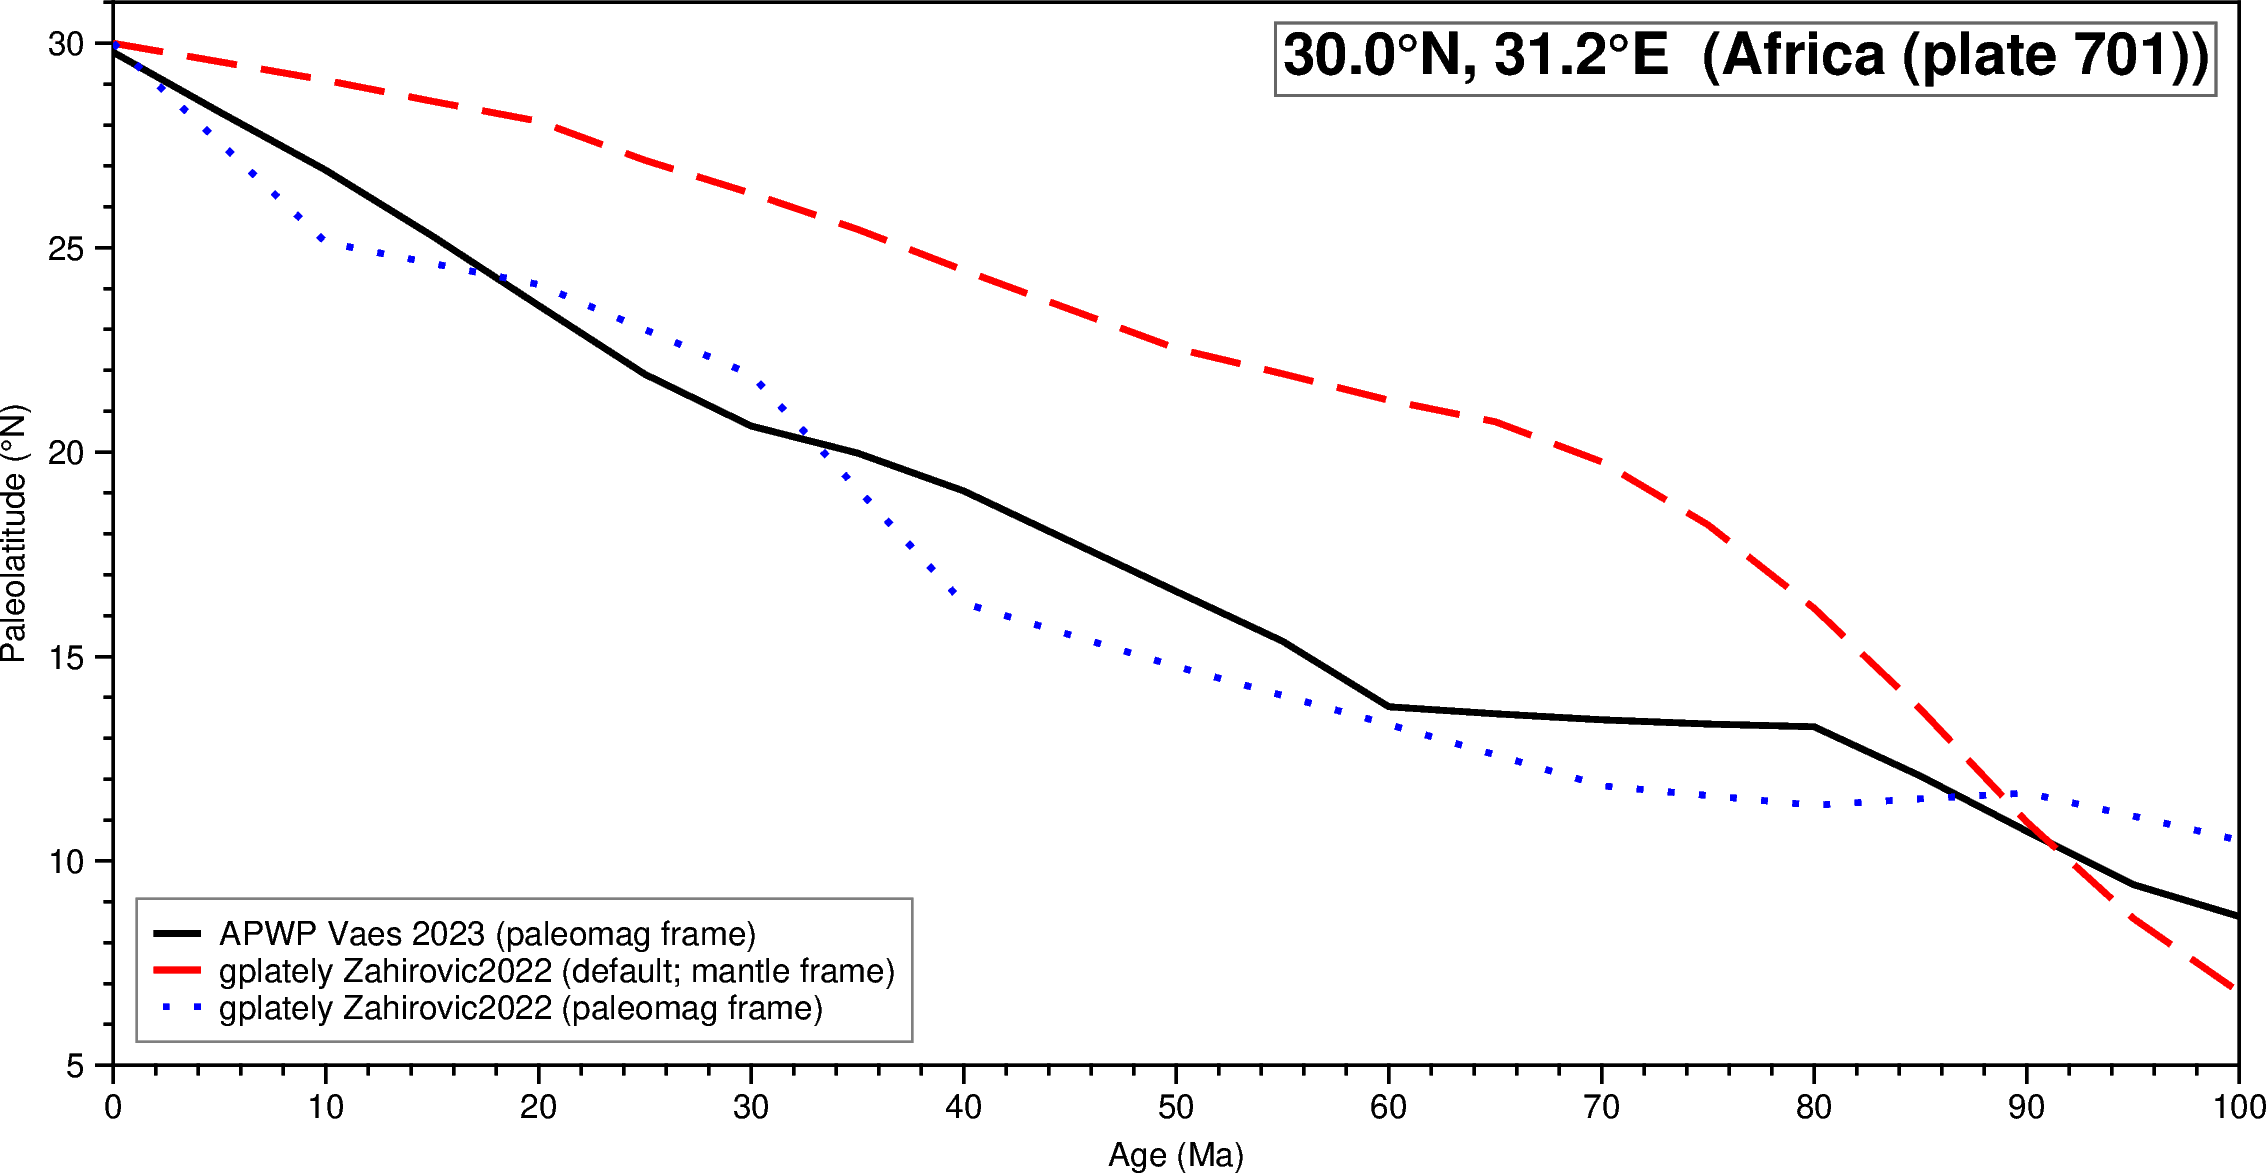

In [5]:
# Cell 4 — comparison plot
# Auto-fit the y-axis to actual data range.
_series = [apwp["paleolat_apwp"].values, recon_paleolats]
if recon_paleolats_pmag is not None:
    _series.append(recon_paleolats_pmag)
combined = np.concatenate(_series)
combined = combined[np.isfinite(combined)]
y_lo = float(np.floor(combined.min() - 1.0))
y_hi = float(np.ceil (combined.max() + 1.0))

deg = "\260"  # GMT degree symbol (avoids backslashes inside f-strings)

fig = pygmt.Figure()
fig.basemap(region=[float(AGES.min()), float(AGES.max()), y_lo, y_hi],
            projection="X18c/9c",
            frame=["xaf+lAge (Ma)", f"yaf+lPaleolatitude ({deg}N)", "WSrt"])

# Black solid — Vaes et al. (2023) APWP (paleomag frame)
fig.plot(x=apwp["age"], y=apwp["paleolat_apwp"],
         pen="1.5p,black", label=apwp_label)

# Red dashed — gplately Zahirovic 2022 default rotation (mantle frame)
fig.plot(x=AGES, y=recon_paleolats,
         pen="1.5p,red,-",
         label=f"gplately {MODEL_NAME} (default; mantle frame)")
# Blue dotted — the same model in its built-in paleomagnetic frame
if recon_paleolats_pmag is not None:
    fig.plot(x=AGES, y=recon_paleolats_pmag,
             pen="1.5p,blue,.",
             label=f"gplately {MODEL_NAME} (paleomag frame)")

fig.legend(position="JBL+jBL+o0.2c", box="+gwhite+p0.5p,gray50")
fig.text(text=f"{SITE_LAT:.1f}{deg}N, {SITE_LON:.1f}{deg}E  ({PLATE_LABEL})",
         position="TR", offset="-0.25c/-0.25c", justify="TR",
         font="14p,Helvetica-Bold,black",
         fill="white", pen="0.6p,gray40")
fig.show(width=900)
display(HTML('<div style="height:1cm"></div>'))


## What the figure shows

Paleolatitude tracks for the Cairo site (30.0°N, 31.2°E), 0–100 Ma:

- **Black solid: APWP Vaes 2023 (paleomagnetic frame).** At each age, the site's paleolatitude is computed as 90° minus the great-circle distance from the site to the interpolated Vaes et al. (2023) pole at that age. By construction, this curve is in the spin-axis (paleomagnetic) reference frame — the only assumption is that the African plate has been rigid and that the global APWP, expressed in South African coordinates, captures Africa's apparent polar wander.
- **Red dashed: gplately Zahirovic 2022, default rotation file (mantle reference frame).** At each age, the present-day site is reconstructed through Zahirovic 2022's rotation chain for plate 701, anchored on plate 0. In this default frame plate 0 stands for a mantle reference frame, so this curve is expressed in the *mantle* frame.
- **Blue dotted: gplately Zahirovic 2022, paleomagnetic frame (701701).** The same model with the built-in paleomagnetic frame as the anchor, which is the like-for-like comparison with the APWP.

**What to read off the figure:**

- *Overall trend.* Cairo moves northward through the Cenozoic, from a lower paleolatitude in the past towards its present 30°N; the exact amount depends on the plate model and the APWP compilation.
- *Gap between the black and red curves.* The offset between the APWP and the mantle-frame reconstruction is the signature of *true polar wander* (TPW): the wholesale rotation of the lithosphere and mantle relative to the spin axis, which the paleomagnetic frame sees and the mantle frame does not. Differences between the APWP and the paleomagnetic data used inside the plate model add a smaller contribution.
- *Blue versus black.* Because both are expressed in a paleomagnetic frame, the remaining difference is the difference between the Vaes et al. (2023) APWP and the paleomagnetic frame built into Zahirovic 2022. The same plot made with the first-order global APWP of Vaes et al. (2023) and Torsvik et al. (2012) in paleomagnetism.org shows the two APWPs to be very close for this part of the Cenozoic.

If the curves cross or diverge in the wrong direction, the most common causes are the lon-first return-order gotcha in `Points.reconstruct(return_array=True)` (always unpack as `rlons, rlats = …`) and an interpolation glitch in the APWP pole longitudes (which is why we unwrap before interpolating in Cell 2).


## Extend this

- **Try a different site.** Set `SITE_LON, SITE_LAT = -25.0, 16.0` for Cape Verde. Cape Verde lies close to the Euler pole of the offset between the two frames, so its paleolatitude changes little and can show both southward and northward motion; it is a good illustration of why the site choice matters. Equatorial and high-latitude sites show the TPW signal differently, because its effect on paleolatitude depends on where the site lies relative to that pole.
- **Add the APWP uncertainty.** The bundled table carries the A95 of every mean pole. Propagate it to a paleolatitude envelope by perturbing the pole within its A95 circle, as in F02, and see how much of the frame difference is significant.
- **Swap plate models.** Compare `"Zahirovic2022"` vs `"Muller2022"` vs `"Merdith2021"`. The model-to-model spread bounds the APWP-fit uncertainty given the reconstruction.
- **Cross-reference F06.** F06 does the same predicted-vs-observed paleolatitude test for a single key pole at one age (the Osler 1.1 Ga pole consistent with the loaded model); this notebook does it as a function of age for one site.

## References

- Vaes, B., van Hinsbergen, D.J.J., van de Lagemaat, S.H.A., van der Wiel, E., Lom, N., Advokaat, E.L., Boschman, L.M., Gallo, L.C., Greve, A., Guilmette, C., Li, S., Lippert, P.C., Montheil, L., Qayyum, A. & Langereis, C.G. (2023). A global apparent polar wander path for the last 320 Ma calculated from site-level paleomagnetic data. *Earth-Sci. Rev.* 245, 104547. https://doi.org/10.1016/j.earscirev.2023.104547.
- Mather, B.R. et al. (2024). Deep time spatio-temporal data analysis using pyGPlates with PlateTectonicTools and GPlately. *Geoscience Data Journal* 11, 3–10.
- Tian, D., Uieda, L., Leong, W.J., et al. (2024). PyGMT: A Python interface for the Generic Mapping Tools. *Zenodo*. https://doi.org/10.5281/zenodo.13679420
- Wessel, P., Luis, J.F., Uieda, L., Scharroo, R., Wobbe, F., Smith, W.H.F. & Tian, D. (2019). The Generic Mapping Tools version 6. *Geochemistry, Geophysics, Geosystems* 20(11), 5556–5564. https://doi.org/10.1029/2019GC008515
- Zahirovic, S., Eleish, A., Doss, S., Pall, J., Cannon, J., Pistone, M., Tetley, M.G., Young, A. & Fox, P. (2022). Subduction and carbonate platform interactions. *Geoscience Data Journal* 9(2), 371-383. https://doi.org/10.1002/gdj3.146
